# BFS Traversal on a Tree and a Graph

**Input (Tree / Graph) → Code (BFS) → Output (Traversal Result)**

Breadth First Search visits nodes level by level. It uses a **queue** (first in, first out), so nodes closer to the start are always visited before nodes further away.

## Step 1: Input tree

```
            A
          /   \
         B     C
        / \   / \
       D   E F   G
      /
     H
```
The tree is stored as an adjacency list (a dictionary).

In [1]:
tree = {
    "A": ["B", "C"],
    "B": ["D", "E"],
    "C": ["F", "G"],
    "D": ["H"],
    "E": [], "F": [], "G": [], "H": [],
}
print(tree)

{'A': ['B', 'C'], 'B': ['D', 'E'], 'C': ['F', 'G'], 'D': ['H'], 'E': [], 'F': [], 'G': [], 'H': []}


## Step 2: BFS code

In [2]:
from collections import deque

def bfs(graph, start):
    visited = [start]
    queue = deque([start])
    order = []
    while queue:
        node = queue.popleft()
        order.append(node)
        print(f"Visit {node:>2} | queue now: {list(queue)}")
        for neighbour in graph.get(node, []):
            if neighbour not in visited:
                visited.append(neighbour)
                queue.append(neighbour)
    return order

## Step 3: Output (traversal result) for the tree

In [3]:
result = bfs(tree, "A")
print("\nBFS traversal:", " -> ".join(result))

Visit  A | queue now: []
Visit  B | queue now: ['C']
Visit  C | queue now: ['D', 'E']
Visit  D | queue now: ['E', 'F', 'G']
Visit  E | queue now: ['F', 'G', 'H']
Visit  F | queue now: ['G', 'H']
Visit  G | queue now: ['H']
Visit  H | queue now: []

BFS traversal: A -> B -> C -> D -> E -> F -> G -> H


### Level by level

In [4]:
def bfs_levels(tree, root):
    levels, queue = [], deque([root])
    while queue:
        level = []
        for _ in range(len(queue)):
            node = queue.popleft()
            level.append(node)
            queue.extend(tree.get(node, []))
        levels.append(level)
    return levels

for i, lvl in enumerate(bfs_levels(tree, "A")):
    print(f"Level {i}: {lvl}")

Level 0: ['A']
Level 1: ['B', 'C']
Level 2: ['D', 'E', 'F', 'G']
Level 3: ['H']


## Step 4: BFS on a graph (with a cycle)

In a graph a node can be reached from more than one path, so the `visited` list stops us from visiting the same node twice.

In [5]:
graph = {
    0: [1, 2],
    1: [0, 3, 4],
    2: [0, 4],
    3: [1, 5],
    4: [1, 2, 5],
    5: [3, 4],
}
result = bfs(graph, 0)
print("\nBFS traversal:", " -> ".join(map(str, result)))

Visit  0 | queue now: []
Visit  1 | queue now: [2]
Visit  2 | queue now: [3, 4]
Visit  3 | queue now: [4]
Visit  4 | queue now: [5]
Visit  5 | queue now: []

BFS traversal: 0 -> 1 -> 2 -> 3 -> 4 -> 5


## Step 5: Draw the tree and show the visit order (matplotlib)

Visit  A | queue now: []
Visit  B | queue now: ['C']
Visit  C | queue now: ['D', 'E']
Visit  D | queue now: ['E', 'F', 'G']
Visit  E | queue now: ['F', 'G', 'H']
Visit  F | queue now: ['G', 'H']
Visit  G | queue now: ['H']
Visit  H | queue now: []


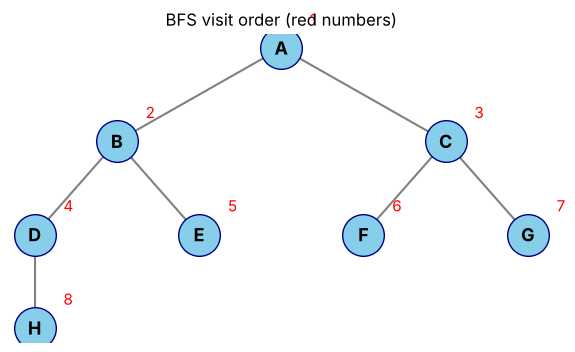

In [6]:
import matplotlib.pyplot as plt

pos = {"A": (4, 3), "B": (2, 2), "C": (6, 2), "D": (1, 1), "E": (3, 1),
       "F": (5, 1), "G": (7, 1), "H": (1, 0)}
order = {n: i + 1 for i, n in enumerate(bfs(tree, "A"))}

fig, ax = plt.subplots(figsize=(7, 4))
for parent, kids in tree.items():
    for k in kids:
        ax.plot(*zip(pos[parent], pos[k]), color="gray", zorder=1)
for n, (x, y) in pos.items():
    ax.scatter(x, y, s=900, color="skyblue", edgecolors="navy", zorder=2)
    ax.text(x, y, n, ha="center", va="center", fontsize=13, weight="bold")
    ax.text(x + 0.35, y + 0.25, str(order[n]), color="red", fontsize=11)
ax.set_title("BFS visit order (red numbers)")
ax.axis("off")
plt.show()

## Conclusion

Tree BFS order: **A → B → C → D → E → F → G → H**  
Graph BFS order (from 0): **0 → 1 → 2 → 3 → 4 → 5**

Time complexity is O(V + E) because every node and every edge is checked once.